# Feature selection, feature engineering, threshold and calibration

The baseline model uses all 13 original features. This notebook asks four questions the baseline does not answer:

1. **Does dropping weak features help?** The EDA showed `fbs` (corr 0.03) and `chol` (0.09) are nearly uninformative.
2. **Does automatic selection help?** A filter (ANOVA F), L1 regularisation and recursive feature elimination.
3. **Do domain-motivated features help?** Heart-rate reserve and clinical threshold flags.
4. **Is 0.5 the right decision threshold, and can the probabilities be trusted?** For a screening tool a missed patient is worse than a false alarm, and the API reports a probability.

**Protocol.** Everything below uses the *training split only*. Variants are compared with repeated stratified 5-fold CV (5 repeats, 25 folds) using the same folds for every variant, so differences are *paired*. Imputers, scalers and selectors sit inside the pipeline, so nothing is fitted on validation folds. Logic lives in `src/experiments.py` (tested in `tests/test_experiments.py`); `python -m src.experiments` logs the same runs to MLflow (experiment `feature-and-threshold-experiments`).

In [1]:
import sys, warnings
from pathlib import Path

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT))
warnings.filterwarnings('ignore')

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from src import experiments as ex

sns.set_theme(style='whitegrid', palette='deep')
FIG = ROOT / 'report' / 'figures'
X_train, X_test, y_train, y_test = ex.split_train_test()
print(f'train={len(X_train)} test={len(X_test)}')
pd.DataFrame([{'variant': v.name, 'what it does': v.description} for v in ex.VARIANTS]).set_index('variant')

train=242 test=61


,what it does
variant,
baseline_all13,all 13 original features (the production model)
drop_fbs_chol,drop fbs and chol (EDA correlation with target...
drop_4_weakest,also drop trestbps and restecg (correlation < ...
filter_kbest14,ANOVA F-test keeps the 14 best encoded columns
l1_select,L1-regularised logistic regression picks the c...
rfe14,recursive feature elimination down to 14 columns
eng_hr_reserve,baseline + heart-rate reserve %
eng_flags,baseline + 4 clinical threshold flags
eng_all,baseline + heart-rate reserve + 4 flags


## 1. Engineered features

Three are standard clinical ideas; the point is to test whether the model gains anything from them.

| feature | definition | reasoning |
|---|---|---|
| `hr_reserve_pct` | `thalach / (220 - age)` | A given peak heart rate means something different at 35 and at 70; this expresses it as a share of the age-predicted maximum. |
| `any_vessel` | `ca > 0` | Collapses the vessel count to the clinically important question: any narrowing at all? |
| `st_depression` | `oldpeak > 0` | Any exercise-induced ST depression. |
| `high_bp`, `high_chol` | `trestbps >= 140`, `chol >= 240` | Conventional hypertension / high-cholesterol cut-offs. |

## 2. Results

In [2]:
results = ex.run_feature_experiments(X_train, y_train, n_repeats=5)
view = results.pivot(index='variant', columns='model', values=['cv_auc', 'delta_vs_baseline', 'delta_se'])
order = [v.name for v in ex.VARIANTS]
summary = pd.DataFrame({
    'LR AUC': view[('cv_auc', 'logistic_regression')], 'LR delta': view[('delta_vs_baseline', 'logistic_regression')],
    'LR SE': view[('delta_se', 'logistic_regression')],
    'RF AUC': view[('cv_auc', 'random_forest')], 'RF delta': view[('delta_vs_baseline', 'random_forest')],
    'RF SE': view[('delta_se', 'random_forest')],
    'columns used': results[results.model == 'logistic_regression'].set_index('variant')['columns_used'],
}).reindex(order).round(4)
summary

,LR AUC,LR delta,LR SE,RF AUC,RF delta,RF SE,columns used
variant,,,,,,,
baseline_all13,0.8923,0.0000,0.0000,0.8928,0.0000,0.0000,28
drop_fbs_chol,0.8980,0.0056,0.0019,0.8964,0.0037,0.0020,25
drop_4_weakest,0.8974,0.0051,0.0031,0.9012,0.0084,0.0020,21
filter_kbest14,0.9051,0.0127,0.0055,0.8961,0.0033,0.0019,14
l1_select,0.8977,0.0053,0.0014,0.8828,-0.0100,0.0018,15
rfe14,0.8839,-0.0084,0.0018,0.8865,-0.0063,0.0032,14
eng_hr_reserve,0.8923,-0.0000,0.0001,0.8936,0.0008,0.0025,29
eng_flags,0.8923,-0.0001,0.0015,0.8987,0.0059,0.0012,36
eng_all,0.8922,-0.0001,0.0015,0.8943,0.0016,0.0025,37


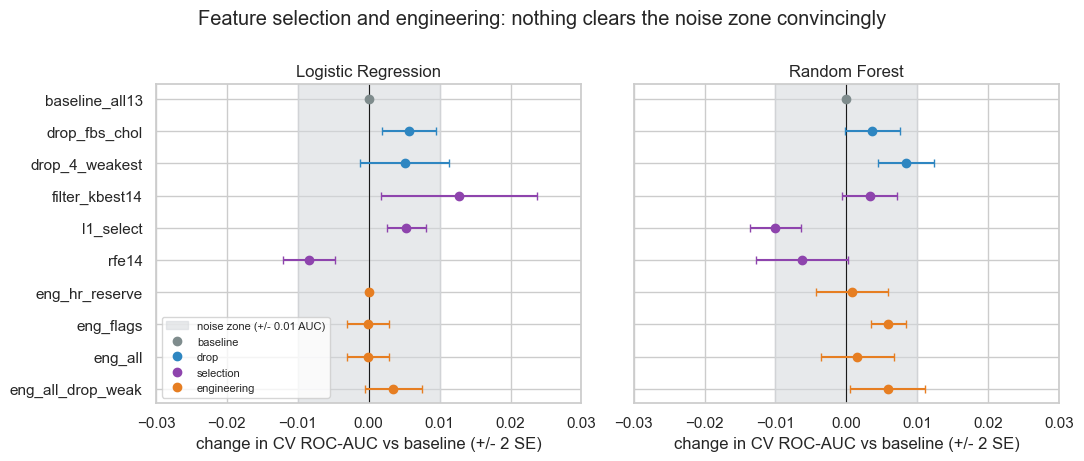

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), sharey=True)
labels = {'logistic_regression': 'Logistic Regression', 'random_forest': 'Random Forest'}
kind = lambda n: ('selection' if n in ('filter_kbest14', 'l1_select', 'rfe14') else
                  'engineering' if n.startswith('eng') else 'drop' if n.startswith('drop') else 'baseline')
colors = {'baseline': '#7f8c8d', 'drop': '#2e86c1', 'selection': '#8e44ad', 'engineering': '#e67e22'}
for ax, (m, g) in zip(axes, results.groupby('model', sort=False)):
    g = g.set_index('variant').reindex(order)
    y = np.arange(len(g))[::-1]
    ax.axvspan(-0.01, 0.01, color='#d5d8dc', alpha=.55, label='noise zone (+/- 0.01 AUC)')
    ax.axvline(0, color='k', lw=.8)
    for yi, (n, r) in zip(y, g.iterrows()):
        ax.errorbar(r.delta_vs_baseline, yi, xerr=2 * r.delta_se, fmt='o', color=colors[kind(n)], capsize=3)
    ax.set_yticks(y); ax.set_yticklabels(g.index); ax.set_xlabel('change in CV ROC-AUC vs baseline (+/- 2 SE)')
    ax.set_title(labels[m]); ax.set_xlim(-0.03, 0.03)
from matplotlib.lines import Line2D
handles = [plt.Rectangle((0, 0), 1, 1, color='#d5d8dc', alpha=.55)] + [Line2D([], [], marker='o', ls='', color=c) for c in colors.values()]
axes[0].legend(handles, ['noise zone (+/- 0.01 AUC)'] + list(colors), loc='lower left', fontsize=8)
fig.suptitle('Feature selection and engineering: nothing clears the noise zone convincingly', y=1.0)
plt.tight_layout(); plt.savefig(FIG / 'feature_experiments.png', dpi=150); plt.show()

### What this shows

- **The baseline is hard to beat.** Repeated CV gives ROC-AUC **0.892** (Logistic Regression) and **0.893** (Random Forest) for all 13 features. Individual folds vary by about 0.04, so a change of 0.01 is a quarter of a fold-to-fold standard deviation. The SE bars here only reflect the 5 repeats, which share the same data, so they are optimistic; treat gaps under about 0.01 as noise.
- **Dropping `fbs` and `chol` is free.** AUC does not fall (LR +0.006, RF +0.004) with 3 fewer encoded columns, which supports the EDA reading that these two carry almost no signal. That is a genuine option for a simpler intake form, but not a reason to change the deployed model.
- **The largest gain, +0.013 for the 14-column ANOVA filter on Logistic Regression, is the best of ten variants I tried.** Picking the winner of many comparisons overstates its benefit, and it does not carry over to Random Forest (+0.003), so I do **not** adopt it.
- **Some automatic selection hurts.** RFE costs -0.008 (LR) and L1 selection costs -0.010 on Random Forest: removing columns from a 242-patient training set throws away information the model can use.
- **The clinical features add nothing for Logistic Regression** (changes of 0.000), probably because the one-hot `ca` and `thal` and the linear `thalach` and `age` already carry what the thresholds and the ratio express. Random Forest gains a little from the threshold flags (+0.006), which is consistent with trees benefiting from explicit cut-points that a linear model can build itself.

**Decision: keep the production model on all 13 original features.** The experiment is documented and reproducible, and it showed that the feature set is not the limiting factor on this dataset.

### Which columns do the automatic selectors keep?

In [4]:
def selected_names(variant_name):
    v = next(v for v in ex.VARIANTS if v.name == variant_name)
    pipe = ex.build_pipeline(v, ex.models()['logistic_regression']).fit(X_train, y_train)
    names = pipe.named_steps['prep'].get_feature_names_out()
    keep = pipe.named_steps['select'].get_support()
    return [n.split('__', 1)[1] for n, k in zip(names, keep) if k]

for name in ('filter_kbest14', 'l1_select'):
    print(f'{name}: {selected_names(name)}\n')

filter_kbest14: ['thalach', 'oldpeak', 'sex_0.0', 'sex_1.0', 'cp_2.0', 'cp_3.0', 'cp_4.0', 'exang_0.0', 'exang_1.0', 'slope_1.0', 'slope_2.0', 'ca_0.0', 'thal_3.0', 'thal_7.0']

l1_select: ['trestbps', 'chol', 'thalach', 'oldpeak', 'sex_0.0', 'sex_1.0', 'cp_4.0', 'restecg_2.0', 'exang_0.0', 'exang_1.0', 'slope_1.0', 'slope_2.0', 'ca_0.0', 'thal_3.0', 'thal_7.0']



## 3. Decision threshold

The model outputs a probability; `prediction` is 1 when it is at least 0.5. That is a convention, not a clinical decision. I used **out-of-fold** probabilities on the training split (every patient scored by a model that never saw them) to trace the precision/recall trade-off, then picked the highest threshold that keeps recall at 90% or more, a screening-style operating point.

In [5]:
tc = ex.threshold_and_calibration(X_train, y_train, X_test, y_test, target_recall=0.90)
curve = tc['curve']
t_s = tc['screening_threshold']
pd.concat([curve[curve.threshold.isin([0.5, t_s])].assign(point=lambda d: np.where(d.threshold == 0.5, 'default 0.5', 'screening'))
           .set_index('point')]).round(3)

,threshold,precision,recall,flagged_share
point,,,,
screening,0.25,0.69,0.901,0.599
default 0.5,0.50,0.87,0.784,0.413


In [6]:
test = pd.DataFrame(tc['test_outcomes']).T
test['missed patients (FN)'] = test['fn']; test['false alarms (FP)'] = test['fp']
print('Held-out test split (28 diseased, 33 healthy):')
test[['threshold', 'tp', 'fn', 'fp', 'tn']]

Held-out test split (28 diseased, 33 healthy):


,threshold,tp,fn,fp,tn
default_0.5,0.50,26.0,2.0,5.0,28.0
screening,0.25,28.0,0.0,10.0,23.0


## 4. Calibration: can `confidence` be trusted as a probability?

In [7]:
bins = tc['calibration_bins']
print(f"Brier score (out-of-fold): {tc['brier']:.3f}   always-predict-the-base-rate: {tc['brier_prevalence_only']:.3f}")
print(f"Expected calibration error (5 equal-frequency bins): {tc['ece']:.3f}")
bins.round(3)

Brier score (out-of-fold): 0.121   always-predict-the-base-rate: 0.248
Expected calibration error (5 equal-frequency bins): 0.030


,mean_predicted,observed_rate,n
0,0.038,0.041,49
1,0.139,0.184,49
2,0.388,0.312,48
3,0.776,0.792,48
4,0.969,0.979,48


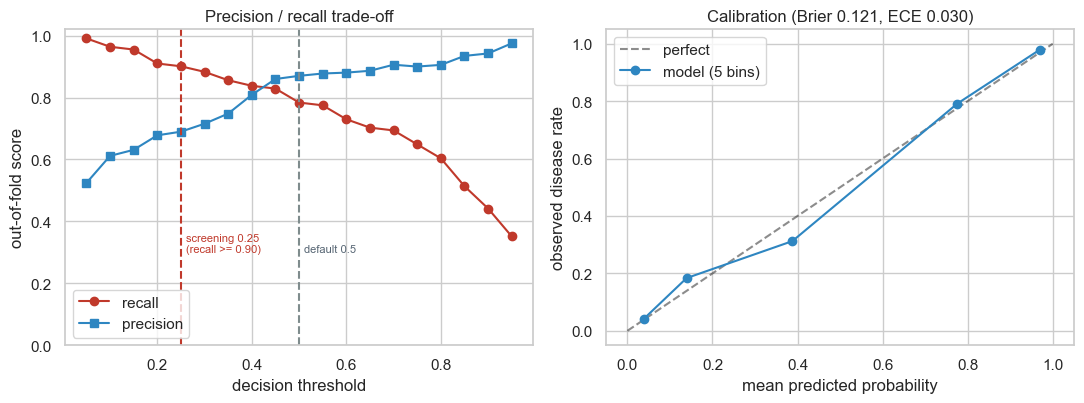

In [8]:
fig, (a, b) = plt.subplots(1, 2, figsize=(11, 4.2))
a.plot(curve.threshold, curve.recall, 'o-', label='recall', color='#c0392b')
a.plot(curve.threshold, curve.precision, 's-', label='precision', color='#2e86c1')
a.axvline(0.5, color='#7f8c8d', ls='--'); a.text(0.51, 0.30, 'default 0.5', color='#566573', fontsize=8)
a.axvline(t_s, color='#c0392b', ls='--'); a.text(t_s + .01, 0.30, f'screening {t_s:.2f}\n(recall >= 0.90)', color='#c0392b', fontsize=8)
a.set_xlabel('decision threshold'); a.set_ylabel('out-of-fold score'); a.set_ylim(0, 1.02)
a.set_title('Precision / recall trade-off'); a.legend(loc='lower left')
b.plot([0, 1], [0, 1], 'k--', alpha=.5, label='perfect')
b.plot(bins.mean_predicted, bins.observed_rate, 'o-', color='#2e86c1', label='model (5 bins)')
b.set_xlabel('mean predicted probability'); b.set_ylabel('observed disease rate')
b.set_title(f"Calibration (Brier {tc['brier']:.3f}, ECE {tc['ece']:.3f})"); b.legend(loc='upper left')
plt.tight_layout(); plt.savefig(FIG / 'threshold_calibration.png', dpi=150); plt.show()

### What this shows

- **At the default 0.5 the model misses about one in five sick patients** in cross-validation (recall 0.78, precision 0.87). Lowering the threshold to **0.25** lifts out-of-fold recall to 0.90 at precision 0.69, and the model then flags 60% of patients instead of 41%.
- **On the held-out split** (28 diseased, 33 healthy) the 0.25 threshold finds all 28 sick patients (0 missed, versus 2 at 0.5) at the cost of 10 false alarms instead of 5. With 61 patients this is an illustration of the trade-off, not a precise estimate.
- **The probabilities are well calibrated.** The Brier score is 0.121 against 0.248 for always predicting the base rate, and the five calibration bins sit close to the diagonal (the largest gap is in the 0.14-0.39 range, where the model is a few points off). So `confidence` and `probability_disease` can be read as risk estimates.

**Decision: leave the API's 0.5 cut-off and document the alternative.** The API returns `probability_disease`, so a client that wants a screening behaviour can apply 0.25 without a redeploy. Choosing the clinical operating point is a policy decision that this coursework model should not make silently.